# 15. 라스트마일 열노출 — 이동권 기반 곤란구간·시설 (재설계)

**프레임**: 폭염 우선관리는 정적 열지도가 아니라 *사람이 목적지 때문에 실외로 걷는 라스트마일*의 문제.
역/정류장(결절점) → 상가(목적지) 보행경로의 **열노출 = 통행흐름 × dose(exp열강도×그늘×시간)**.

**필요**: `osmnx`(보행망), 외부수집 `data/interim/transit_nodes.geojson`·`data/processed/store_density_grid.csv`,
로컬결과 `data/results/heat_index_utci.geojson`·`data/processed/grid_features.geojson`. **로컬 전용**(COMPAS엔 osmnx 없음).

산출: `lastmile_bottleneck`(노출) · `heat_difficulty_zones`(과제3 곤란) · `facility_priority_v2`(과제4 시설).
**주의**: 전체 실행 ~5분(보행망 빌드+557 출발지 라우팅).

In [1]:
# ── 실행 환경 가드 (하이브리드 전략, 실행순서.md §1 참조) ──────────────
# 이 노트북은 '로컬 사전계산' 단계입니다. COMPAS에는 ['osmnx'] 이(가) 없으므로
# 그 경우 아래 셀들은 자동으로 건너뛰고(LOCAL_RUN=False) 동봉 산출물만 검증합니다.
# 산출물은 제출 데이터 ZIP에 포함되어 있어 후속 노트북은 그대로 실행됩니다.
import importlib.util, pathlib
_DEPS = ['osmnx']
_missing = [m for m in _DEPS if importlib.util.find_spec(m) is None]
LOCAL_RUN = not _missing
_ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
if LOCAL_RUN:
    print("[로컬 모드] 의존성 충족 - 전체 셀을 실행합니다.")
else:
    print("[COMPAS 모드] 미설치 의존성:", _missing, "-> 아래 셀은 건너뜁니다.")
    print("이 단계의 동봉 산출물 검증:")
    for _f in ['data/results/lastmile_bottleneck.geojson', 'data/results/heat_difficulty_zones.geojson', 'data/results/facility_priority_v2.geojson', 'data/results/lastmile_od.csv']:
        _p = _ROOT / _f
        if _p.exists():
            print("  [OK]", _f, "(%.1f MB)" % (_p.stat().st_size / 1e6))
        else:
            print("  [!!]", _f, "없음 - 제출 데이터 ZIP의 해당 파일을 이 경로에 두십시오.")


[로컬 모드] 의존성 충족 - 전체 셀을 실행합니다.


In [2]:
if LOCAL_RUN:
    import sys, pathlib
    sys.path.append(str(pathlib.Path.cwd().parent))
    import numpy as np, pandas as pd, geopandas as gpd
    from shapely.geometry import LineString
    from src.config import (DATA_RESULTS, DATA_PROCESSED, DATA_INTERIM, GRID_30M,
                            OUT_FIGURES, OUT_MAPS)
    from src.network.lastmile import build_walk_graph, lastmile_exposure
    from src.network.facility import cluster_intervention
    from src.network.difficulty import analyze_difficulty

    # 1) 보행망 + 격자 UTCI/그늘 → dose 그래프 (~70s)
    G, node_xy = build_walk_graph(DATA_RESULTS / 'heat_index_utci.geojson',
                                  DATA_PROCESSED / 'grid_features.geojson')
    print('walk graph:', G.number_of_nodes(), 'nodes', G.number_of_edges(), 'edges')

walk graph: 17940 nodes 23295 edges


In [3]:
if LOCAL_RUN:
    # 2) 출발지(역출입구+버스정류장) + 출발지가중(상가활동 200m) + 목적지(상가밀도격자)
    tn = gpd.read_file(DATA_INTERIM / 'transit_nodes.geojson')
    org = tn[tn['type'].isin(['entrance', 'bus'])].to_crs(32652).reset_index(drop=True)
    poi = gpd.read_file(DATA_INTERIM / 'poi_seongnam_clip.geojson').to_crs(32652)
    buf = org.copy(); buf['geometry'] = buf.geometry.buffer(200); buf['oi'] = range(len(buf))
    pj = gpd.sjoin(poi[['geometry']], buf[['oi', 'geometry']], predicate='within')
    ow = pj.groupby('oi').size().reindex(range(len(org))).fillna(0).to_numpy(float)
    ow = ow + ow[ow > 0].mean() * 0.1                       # 0 방출 방지
    org4 = org.to_crs(4326); origins = list(zip(org4.geometry.x, org4.geometry.y))

    dens = pd.read_csv(DATA_PROCESSED / 'store_density_grid.csv')
    dens = dens[dens.n_all >= 10]
    grid = gpd.read_file(GRID_30M)[['grid_id', 'geometry']]
    gd = grid.merge(dens[['grid_id', 'n_all']], on='grid_id')
    cen = gd.to_crs(32652).geometry.centroid.to_crs(4326)
    dests = list(zip(cen.x, cen.y)); dest_w = gd['n_all'].to_numpy(float)
    print('출발지 %d(출입구+버스) / 목적지 %d(상가격자)' % (len(origins), len(dests)))

출발지 557(출입구+버스) / 목적지 500(상가격자)


In [4]:
if LOCAL_RUN:
    # 3) 라스트마일 노출 라우팅 (~5min) — 최단 vs 열회피, 흐름=출발가중×목적끌림×거리감쇠
    edge_expo, edge_flow, od = lastmile_exposure(G, node_xy, origins, dests, dest_w,
                                                 origin_w=ow, max_m=1200, decay_m=400)
    rows = [{'expo': e, 'flow': edge_flow[k], 'utci': G[k[0]][k[1]]['utci'],
             'sun': G[k[0]][k[1]]['sun'],
             'geometry': LineString([node_xy[k[0]], node_xy[k[1]]])}
            for k, e in edge_expo.items()]
    bl = gpd.GeoDataFrame(rows, crs=4326)
    bl['expo_norm'] = bl['expo'] / bl['expo'].max()
    bl.to_file(DATA_RESULTS / 'lastmile_bottleneck.geojson', driver='GeoJSON')
    odf = pd.DataFrame(od)
    odf.to_csv(DATA_RESULTS / 'lastmile_od.csv', index=False)   # 재현·통계용 OD 레코드 보존
    # 귀무모델·회피가능성 검증
    rho = bl['expo'].corr(bl['flow'], method='spearman')
    ratio = 1 - odf.min_dose / odf.short_dose.replace(0, np.nan)
    avoid = ratio.median()
    print('노출링크 %d | OD %d' % (len(bl), len(odf)))
    print('귀무모델 rho(노출vs흐름) %.3f (1이면 열무의미)' % rho)
    print('열회피 dose감소 중앙 %.1f%% / 평균 %.1f%% (라스트마일 짧아 우회실익 작음)' % (100 * avoid, 100 * ratio.mean()))

노출링크 4971 | OD 20953
귀무모델 rho(노출vs흐름) 0.886 (1이면 열무의미)
열회피 dose감소 중앙 3.5% / 평균 7.3% (라스트마일 짧아 우회실익 작음)


In [5]:
if LOCAL_RUN:
    # 4) 과제4 시설 우선지역 — 병목 상위10%% 링크 근접클러스터 → 개입구역
    st = tn[tn['type'] == 'station'].dropna(subset=['name'])
    fac = cluster_intervention(bl, st, top_q=0.9, link_m=80)
    fac.to_file(DATA_RESULTS / 'facility_priority_v2.geojson', driver='GeoJSON')
    byst = fac.groupby('station')['expo_share'].sum().sort_values(ascending=False)
    top_frac = bl.loc[bl['expo'] >= bl['expo'].quantile(0.9), 'expo'].sum() / bl['expo'].sum()
    print('개입구역 %d개 (상위10%% 병목 노출의 %.0f%% = 전체 병목 노출의 %.0f%% 커버)'
          % (len(fac), 100 * fac['expo_share'].sum(), 100 * fac['expo_share'].sum() * top_frac))
    print('역별 노출비중:', {k: round(100 * v, 1) for k, v in byst.items()})

개입구역 43개 (상위10% 병목 노출의 92% = 전체 병목 노출의 72% 커버)
역별 노출비중: {'미금': 19.2, '야탑': 17.4, '서현': 16.6, '판교': 14.4, '수내': 11.1, '정자': 8.1, '오리': 5.2}


In [6]:
if LOCAL_RUN:
    # 5) 과제3 곤란구간 — 원인 분해(통행/그늘부재/회피불가)
    diff = analyze_difficulty(bl)
    diff.to_file(DATA_RESULTS / 'heat_difficulty_zones.geojson', driver='GeoJSON')
    hi = diff[diff['difficulty'] >= diff['difficulty'].quantile(0.9)]
    print('곤란 상위10%% = %d링크' % len(hi))
    print('원인유형:', {k: '%d(%.0f%%)' % (v, 100*v/len(hi)) for k, v in hi['cause'].value_counts().items()})
    print('회피불가(그늘대안<15%%): 전체 %.0f%% / 곤란상위 %.0f%%'
          % (100*diff['unavoidable'].mean(), 100*hi['unavoidable'].mean()))

곤란 상위10% = 498링크
원인유형: {'땡볕형': '331(66%)', '복합': '159(32%)', '통행형': '8(2%)'}
회피불가(그늘대안<15%): 전체 32% / 곤란상위 35%


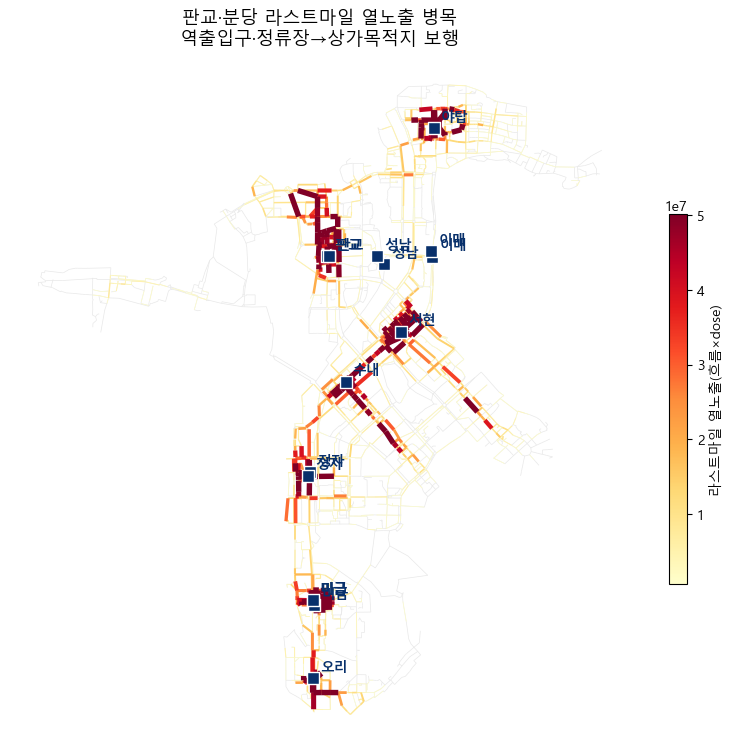

In [7]:
if LOCAL_RUN:
    # 6) 시각화 — 병목 정적지도(보고서 fig17)
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from src.viz.fonts import setup_font
    setup_font()   # 한글 폰트 자동 적용(COMPAS 미보유 시 동봉 폰트 등록)
    blm = bl.to_crs(3857); stm = st.to_crs(3857)
    fig, ax = plt.subplots(figsize=(10, 12))
    blm.plot(ax=ax, color='#e8e8e8', linewidth=0.5, zorder=1)
    vmax = blm['expo'].quantile(0.97)
    top = blm[blm['expo'] > blm['expo'].quantile(0.5)].sort_values('expo').copy()
    top['e'] = top['expo'].clip(upper=vmax)
    top.plot(ax=ax, column='e', cmap='YlOrRd', linewidth=top['e']/vmax*3.5+0.4, zorder=2,
             legend=True, legend_kwds={'shrink': 0.4, 'label': '라스트마일 열노출(흐름×dose)'})
    ax.scatter(stm.geometry.x, stm.geometry.y, s=80, c='#08306b', marker='s',
               edgecolor='white', linewidth=1, zorder=4)
    for _, r in stm.iterrows():
        ax.annotate(r['name'], (r.geometry.x, r.geometry.y), fontsize=10, fontweight='bold',
                    color='#08306b', xytext=(5, 5), textcoords='offset points', zorder=5)
    ax.set_title('판교·분당 라스트마일 열노출 병목\n역출입구·정류장→상가목적지 보행', fontsize=13)
    ax.set_axis_off()
    OUT_FIGURES.mkdir(parents=True, exist_ok=True)
    plt.savefig(OUT_FIGURES / 'fig17_lastmile_bottleneck.png', dpi=110, bbox_inches='tight')
    plt.show()